# Apple Stock

### Introduction:

We are going to use Apple's stock price.


### Step 1. Import the necessary libraries

In [31]:
import pandas as pd
import numpy as np

### Step 2. Import the dataset from this [address](https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/09_Time_Series/Apple_Stock/appl_1980_2014.csv)

In [32]:
url = 'https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/09_Time_Series/Apple_Stock/appl_1980_2014.csv'

### Step 3. Assign it to a variable apple and apply a head()

In [33]:
apple = pd.read_csv(url)
apple.head()

,Date,Open,High,Low,Close,Volume,Adj Close
0,2014-07-08,96.27,96.80,93.92,95.35,65130000,95.35
1,2014-07-07,94.14,95.99,94.10,95.97,56305400,95.97
2,2014-07-03,93.67,94.10,93.20,94.03,22891800,94.03
3,2014-07-02,93.87,94.06,93.09,93.48,28420900,93.48
4,2014-07-01,93.52,94.07,93.13,93.52,38170200,93.52


### Step 4.  Check out the type of the columns

In [34]:
apple.dtypes

Date          object
Open         float64
High         float64
Low          float64
Close        float64
Volume         int64
Adj Close    float64
dtype: object

### Step 5. Transform the Date column as a datetime type and check the info()

In [35]:
apple['Date'] = pd.to_datetime(apple['Date'])
apple.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8465 entries, 0 to 8464
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       8465 non-null   datetime64[ns]
 1   Open       8465 non-null   float64       
 2   High       8465 non-null   float64       
 3   Low        8465 non-null   float64       
 4   Close      8465 non-null   float64       
 5   Volume     8465 non-null   int64         
 6   Adj Close  8465 non-null   float64       
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 463.1 KB


### Step 6.  Set the date as the index

In [36]:
apple = apple.set_index(['Date'])
apple.head()

,Open,High,Low,Close,Volume,Adj Close
Date,,,,,,
2014-07-08,96.27,96.80,93.92,95.35,65130000,95.35
2014-07-07,94.14,95.99,94.10,95.97,56305400,95.97
2014-07-03,93.67,94.10,93.20,94.03,22891800,94.03
2014-07-02,93.87,94.06,93.09,93.48,28420900,93.48
2014-07-01,93.52,94.07,93.13,93.52,38170200,93.52


### Step 7.  Is there any duplicate dates?

In [37]:
print(apple.index.has_duplicates)

False


### Step 8.  Ops...it seems the index is from the most recent date. Make the first entry the oldest date.

In [38]:
apple_o = apple.sort_index()
apple_o.head()

,Open,High,Low,Close,Volume,Adj Close
Date,,,,,,
1980-12-12,28.75,28.87,28.75,28.75,117258400,0.45
1980-12-15,27.38,27.38,27.25,27.25,43971200,0.42
1980-12-16,25.37,25.37,25.25,25.25,26432000,0.39
1980-12-17,25.87,26.00,25.87,25.87,21610400,0.40
1980-12-18,26.63,26.75,26.63,26.63,18362400,0.41


### Step 9. Get the last business day of each month

In [39]:
anios_mes = apple_o.index.to_period('M').unique()
inis_mes = anios_mes.to_timestamp()
ult_dias_mes = inis_mes + pd.offsets.MonthEnd(0)
ult_dias_lab = []
for elm in ult_dias_mes:
    if elm.weekday() >= 5:
        ult_dias_lab.append(elm - pd.offsets.BDay(1))
    else:
        ult_dias_lab.append(elm)
ult_dias_lab

[Timestamp('1980-12-31 00:00:00'),
 Timestamp('1981-01-30 00:00:00'),
 Timestamp('1981-02-27 00:00:00'),
 Timestamp('1981-03-31 00:00:00'),
 Timestamp('1981-04-30 00:00:00'),
 Timestamp('1981-05-29 00:00:00'),
 Timestamp('1981-06-30 00:00:00'),
 Timestamp('1981-07-31 00:00:00'),
 Timestamp('1981-08-31 00:00:00'),
 Timestamp('1981-09-30 00:00:00'),
 Timestamp('1981-10-30 00:00:00'),
 Timestamp('1981-11-30 00:00:00'),
 Timestamp('1981-12-31 00:00:00'),
 Timestamp('1982-01-29 00:00:00'),
 Timestamp('1982-02-26 00:00:00'),
 Timestamp('1982-03-31 00:00:00'),
 Timestamp('1982-04-30 00:00:00'),
 Timestamp('1982-05-31 00:00:00'),
 Timestamp('1982-06-30 00:00:00'),
 Timestamp('1982-07-30 00:00:00'),
 Timestamp('1982-08-31 00:00:00'),
 Timestamp('1982-09-30 00:00:00'),
 Timestamp('1982-10-29 00:00:00'),
 Timestamp('1982-11-30 00:00:00'),
 Timestamp('1982-12-31 00:00:00'),
 Timestamp('1983-01-31 00:00:00'),
 Timestamp('1983-02-28 00:00:00'),
 Timestamp('1983-03-31 00:00:00'),
 Timestamp('1983-04-

### Step 10.  What is the difference in days between the first day and the oldest

In [40]:
apple_o.index[-1] - apple_o.index[0]

Timedelta('12261 days 00:00:00')

### Step 11.  How many months in the data we have?

In [41]:
anios_mes = apple_o.index.to_period('M')
num_anios_mes_distintos = anios_mes.nunique()
num_anios_mes_distintos

404

### Step 12. Plot the 'Adj Close' value. Set the size of the figure to 13.5 x 9 inches

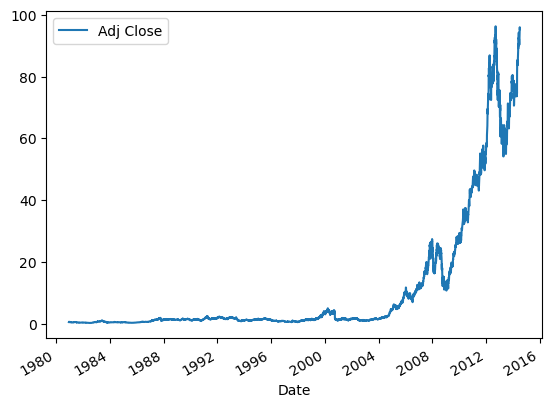

In [42]:
apple_o.plot(y='Adj Close');